In [13]:
# import all required libraries

import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor # For regression task
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report,recall_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [14]:
# Reading the data
data = pd.read_csv("C:/Users/periy/Downloads/archive/ObesityDataSet_raw_and_data_sinthetic.csv") 
data.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [15]:
data.duplicated().sum()

np.int64(24)

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [5]:
data.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE',
       'CALC', 'MTRANS', 'NObeyesdad'],
      dtype='object')

In [7]:
data.shape

(2111, 17)

In [8]:
# Get the statistical information of the data
data.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [9]:
# Cheking for null values
data.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

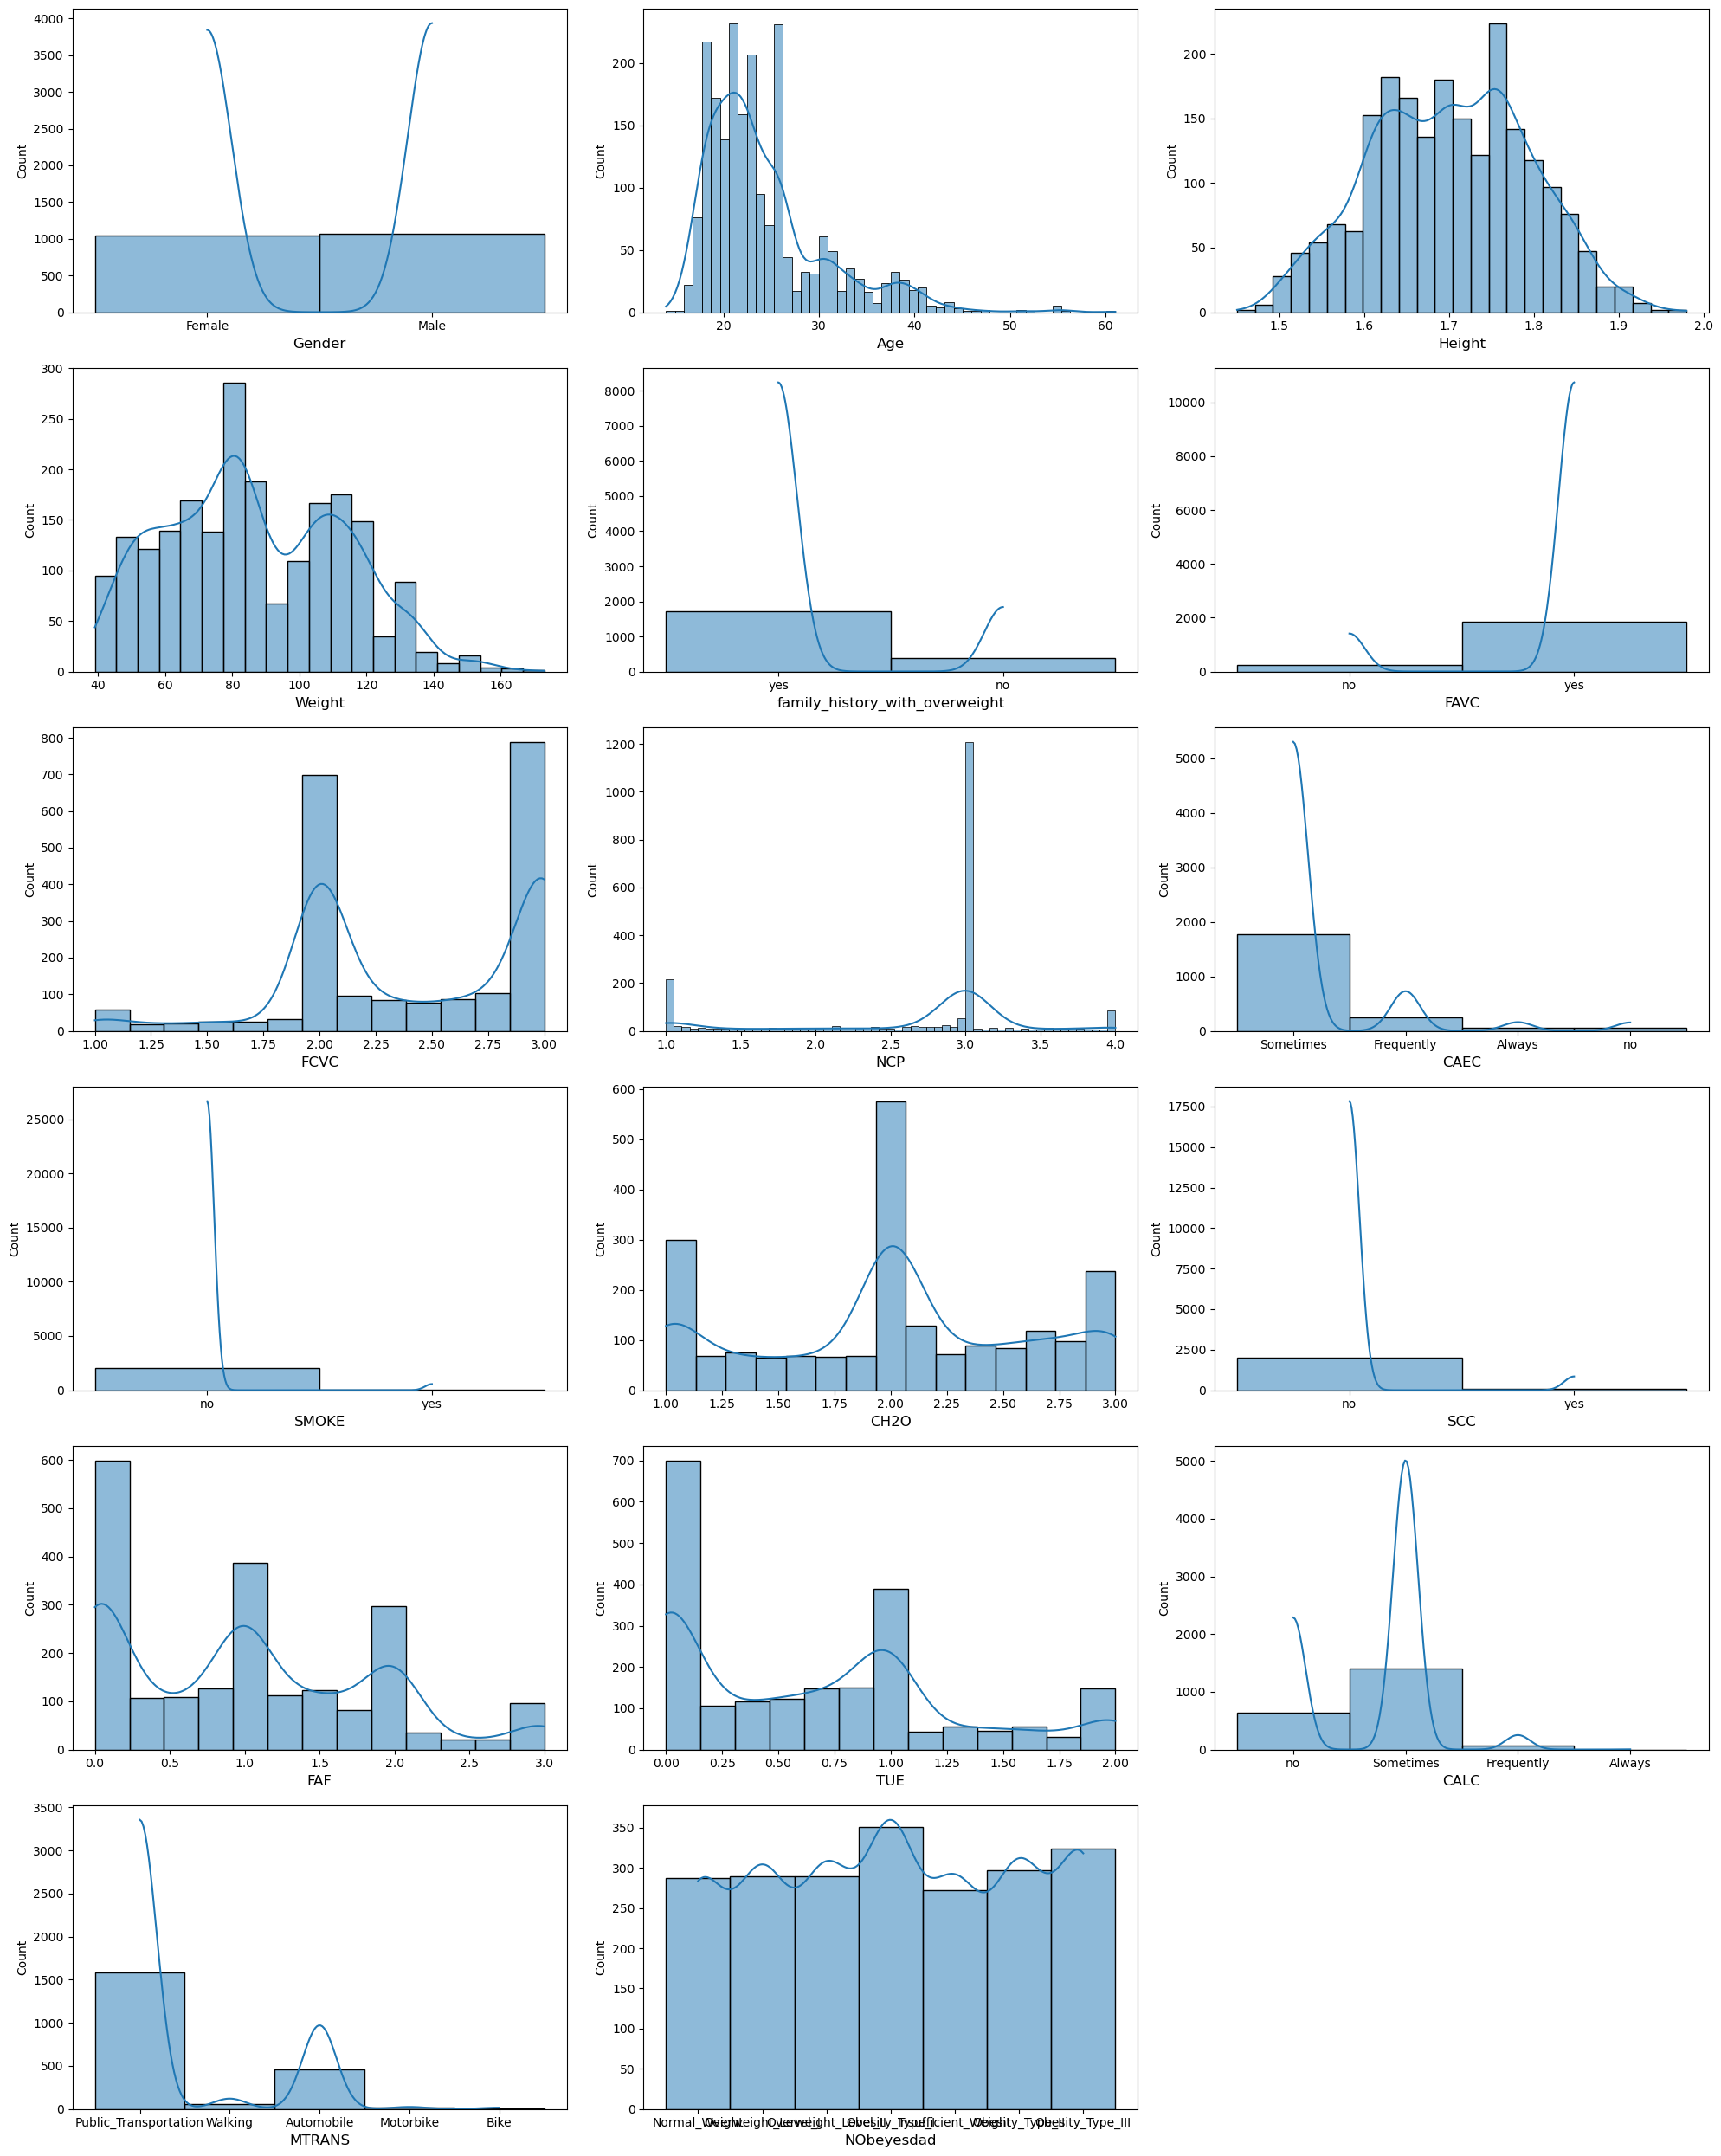

In [12]:
plt.figure(figsize=(20, 25), facecolor='white')
plotnumber = 1

for column in data.columns:
    if plotnumber <= 17:
        plt.subplot(6, 3, plotnumber)   # 6 rows × 3 columns = 18 plots
        sns.histplot(data[column], kde=True)
        plt.xlabel(column, fontsize=12)

    plotnumber += 1

plt.tight_layout()
plt.show()

In [16]:
data["NObeyesdad"].value_counts()

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

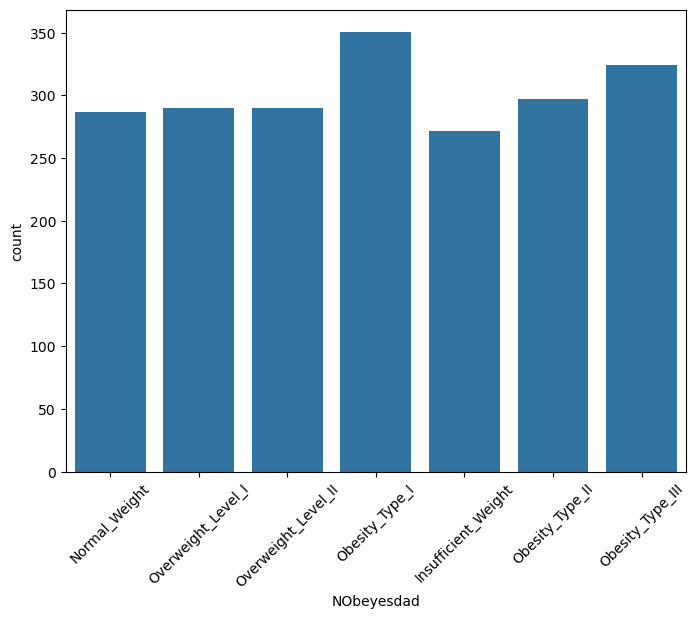

In [17]:
plt.figure(figsize=(8,6))

sns.countplot(x="NObeyesdad", data=data)

plt.xticks(rotation=45)

plt.show()

In [27]:
X.dtypes

Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
dtype: object

In [28]:
# Separate features and target
X = data.drop("NObeyesdad", axis=1)
y = data["NObeyesdad"]

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

In [31]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 23 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 2111 non-null   float64
 1   Height                              2111 non-null   float64
 2   Weight                              2111 non-null   float64
 3   FCVC                                2111 non-null   float64
 4   NCP                                 2111 non-null   float64
 5   CH2O                                2111 non-null   float64
 6   FAF                                 2111 non-null   float64
 7   TUE                                 2111 non-null   float64
 8   Gender_Male                         2111 non-null   bool   
 9   family_history_with_overweight_yes  2111 non-null   bool   
 10  FAVC_yes                            2111 non-null   bool   
 11  CAEC_Frequently                     2111 no

In [38]:
data["NObeyesdad"].head()

[1 1 1 5 6 1 1 1 1 1]


In [35]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

In [37]:
data["NObeyesdad"].head()

0          Normal_Weight
1          Normal_Weight
2          Normal_Weight
3     Overweight_Level_I
4    Overweight_Level_II
Name: NObeyesdad, dtype: object

In [39]:
print(y[:10])

[1 1 1 5 6 1 1 1 1 1]


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [49]:
## taking optimal k to determine how many nearest neighbors  to create

# create a list to store the error values for each k
error_rate = []

# Will take some time
for i in range(1,11):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train,y_train)
    pred_i = knn.predict(X_test)
    error_rate.append(np.mean(pred_i != y_test))

In [50]:
error_rate

[np.float64(0.17966903073286053),
 np.float64(0.1867612293144208),
 np.float64(0.17494089834515367),
 np.float64(0.1773049645390071),
 np.float64(0.1773049645390071),
 np.float64(0.19621749408983452),
 np.float64(0.19621749408983452),
 np.float64(0.2033096926713948),
 np.float64(0.21513002364066194),
 np.float64(0.21513002364066194)]

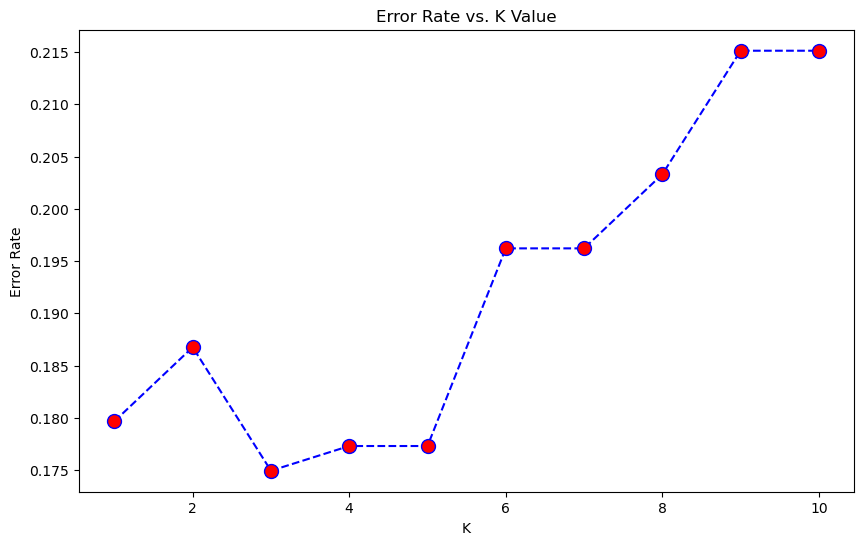

In [51]:
# Lets plot the k-value and error rate

plt.figure(figsize=(10,6))
plt.plot(range(1,11),error_rate,color='blue', linestyle='dashed', 
         marker='o',markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.show()

In [53]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

accuracy = []

for k in range(1, 21):

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)

    accuracy.append(acc)

    print("Accuracy for K =", k, "is:", acc)

Accuracy for K = 1 is: 0.8203309692671394
Accuracy for K = 2 is: 0.8132387706855791
Accuracy for K = 3 is: 0.8250591016548463
Accuracy for K = 4 is: 0.8226950354609929
Accuracy for K = 5 is: 0.8226950354609929
Accuracy for K = 6 is: 0.8037825059101655
Accuracy for K = 7 is: 0.8037825059101655
Accuracy for K = 8 is: 0.7966903073286052
Accuracy for K = 9 is: 0.7848699763593381
Accuracy for K = 10 is: 0.7848699763593381
Accuracy for K = 11 is: 0.7754137115839244
Accuracy for K = 12 is: 0.7754137115839244
Accuracy for K = 13 is: 0.7659574468085106
Accuracy for K = 14 is: 0.7588652482269503
Accuracy for K = 15 is: 0.75177304964539
Accuracy for K = 16 is: 0.7470449172576832
Accuracy for K = 17 is: 0.7328605200945626
Accuracy for K = 18 is: 0.7304964539007093
Accuracy for K = 19 is: 0.7186761229314421
Accuracy for K = 20 is: 0.7163120567375887


In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [40]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [41]:
y_pred = knn.predict(X_test)

In [42]:
y_pred

array(['Insufficient_Weight', 'Obesity_Type_III', 'Normal_Weight',
       'Insufficient_Weight', 'Overweight_Level_I', 'Insufficient_Weight',
       'Obesity_Type_II', 'Obesity_Type_I', 'Obesity_Type_I',
       'Insufficient_Weight', 'Obesity_Type_I', 'Obesity_Type_III',
       'Obesity_Type_II', 'Obesity_Type_II', 'Obesity_Type_III',
       'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_II',
       'Obesity_Type_I', 'Overweight_Level_II', 'Obesity_Type_I',
       'Overweight_Level_I', 'Obesity_Type_III', 'Obesity_Type_I',
       'Normal_Weight', 'Overweight_Level_II', 'Overweight_Level_II',
       'Obesity_Type_III', 'Obesity_Type_III', 'Insufficient_Weight',
       'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II',
       'Overweight_Level_II', 'Insufficient_Weight', 'Obesity_Type_III',
       'Obesity_Type_I', 'Normal_Weight', 'Normal_Weight',
       'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II',
       'Normal_Weight', 'Normal_Weight', 'Overweight_Lev

In [46]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8226950354609929


In [47]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[50  3  0  0  0  3  0]
 [13 33  5  0  0  6  5]
 [ 0  2 70  2  0  2  2]
 [ 1  0  0 56  0  0  1]
 [ 0  0  0  0 63  0  0]
 [ 2  9  3  1  0 40  1]
 [ 0  2  5  3  1  3 36]]


In [48]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                     precision    recall  f1-score   support

Insufficient_Weight       0.76      0.89      0.82        56
      Normal_Weight       0.67      0.53      0.59        62
     Obesity_Type_I       0.84      0.90      0.87        78
    Obesity_Type_II       0.90      0.97      0.93        58
   Obesity_Type_III       0.98      1.00      0.99        63
 Overweight_Level_I       0.74      0.71      0.73        56
Overweight_Level_II       0.80      0.72      0.76        50

           accuracy                           0.82       423
          macro avg       0.81      0.82      0.81       423
       weighted avg       0.82      0.82      0.82       423



In [55]:
from sklearn.metrics import recall_score

recall1 = recall_score(y_test, y_pred, average='weighted')

print("Recall:", recall1)

Recall: 0.8226950354609929


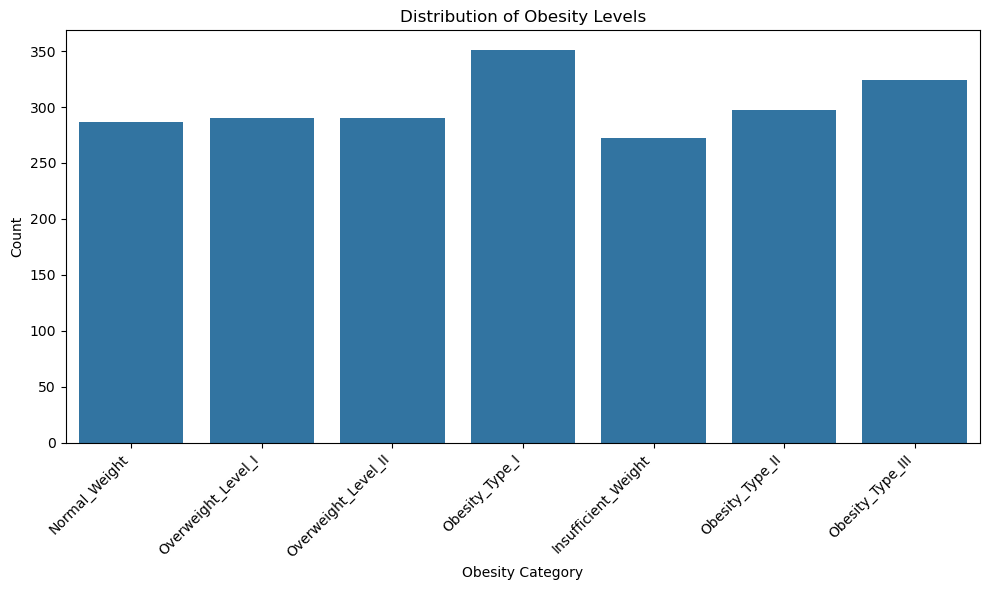

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.countplot(x="NObeyesdad", data=data)

plt.xticks(rotation=45, ha='right')

plt.title("Distribution of Obesity Levels")
plt.xlabel("Obesity Category")
plt.ylabel("Count")

plt.tight_layout()

plt.show()

In [60]:
data["NObeyesdad"].value_counts()

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

In [61]:
df=sns.load_dataset('iris')

In [62]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


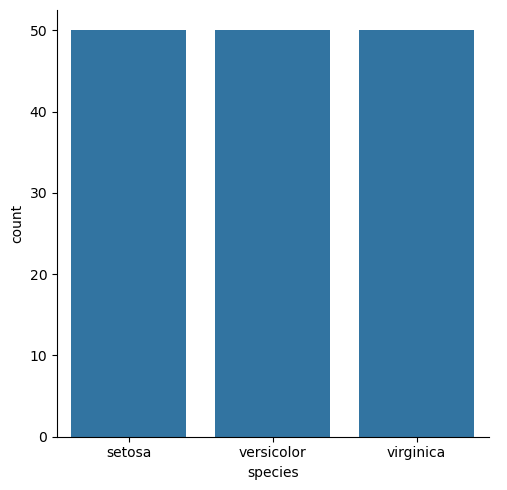

In [63]:
sns.catplot(x='species',data=df,kind='count') # Balanced dataset

In [64]:
!pip install imblearn


In [65]:
conda install --user glemaitre imbalanced-learn 


Note: you may need to restart the kernel to use updated packages.


usage: conda-script.py [-h] [-v] [--no-plugins] [-V] COMMAND ...
conda-script.py: error: unrecognized arguments: --user


In [66]:
!pip install -U imbalanced-learn

In [67]:
from imblearn.over_sampling import SMOTE
smote = SMOTE() 

In [68]:
y_train.value_counts()

NObeyesdad
Obesity_Type_I         273
Obesity_Type_III       261
Overweight_Level_II    240
Obesity_Type_II        239
Overweight_Level_I     234
Normal_Weight          225
Insufficient_Weight    216
Name: count, dtype: int64

In [69]:
X_train_smote, y_train_smote = smote.fit_resample(X_train.astype('float'),
                                                  y_train)

In [70]:
y_train_smote.value_counts()

NObeyesdad
Normal_Weight          273
Obesity_Type_III       273
Obesity_Type_I         273
Insufficient_Weight    273
Obesity_Type_II        273
Overweight_Level_II    273
Overweight_Level_I     273
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='NObeyesdad'>

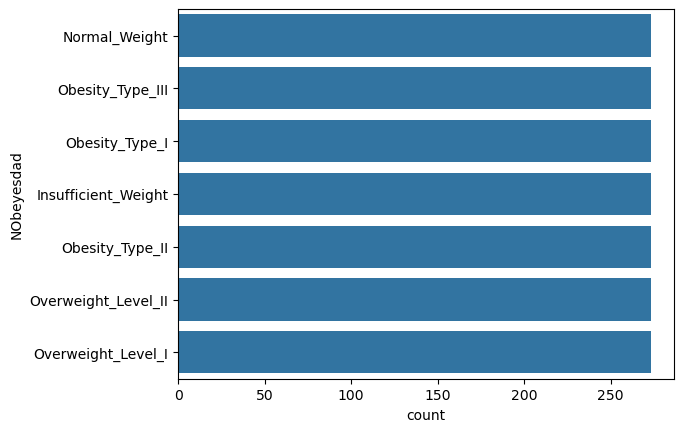

In [71]:
sns.countplot(y_train_smote)

<Axes: ylabel='count'>

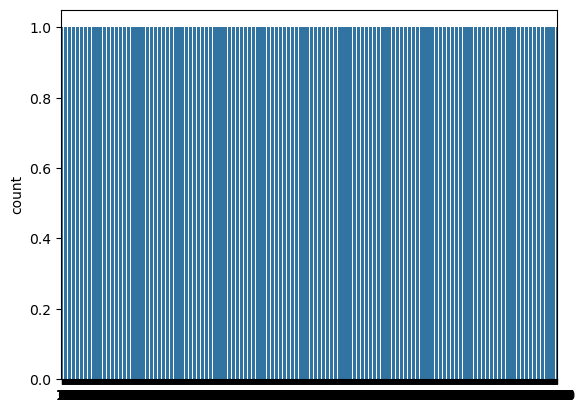

In [74]:
sns.countplot(y) 

In [75]:
from collections import Counter
print("Actual Classes",Counter(y_train))
print("SMOTE Classes",Counter(y_train_smote))

Actual Classes Counter({'Obesity_Type_I': 273, 'Obesity_Type_III': 261, 'Overweight_Level_II': 240, 'Obesity_Type_II': 239, 'Overweight_Level_I': 234, 'Normal_Weight': 225, 'Insufficient_Weight': 216})
SMOTE Classes Counter({'Normal_Weight': 273, 'Obesity_Type_III': 273, 'Obesity_Type_I': 273, 'Insufficient_Weight': 273, 'Obesity_Type_II': 273, 'Overweight_Level_II': 273, 'Overweight_Level_I': 273})


In [76]:

knn2 = KNeighborsClassifier(n_neighbors=5)
knn2.fit(X_train_smote, y_train_smote)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [77]:
y_pred = knn2.predict(X_test)

In [78]:
print("The accuracy score is : ", accuracy_score(y_test,y_pred))

The accuracy score is :  0.8108747044917257


In [79]:
print(classification_report(y_test,y_pred))

                     precision    recall  f1-score   support

Insufficient_Weight       0.73      0.86      0.79        56
      Normal_Weight       0.63      0.50      0.56        62
     Obesity_Type_I       0.85      0.88      0.87        78
    Obesity_Type_II       0.92      0.97      0.94        58
   Obesity_Type_III       0.98      1.00      0.99        63
 Overweight_Level_I       0.69      0.71      0.70        56
Overweight_Level_II       0.82      0.72      0.77        50

           accuracy                           0.81       423
          macro avg       0.80      0.81      0.80       423
       weighted avg       0.81      0.81      0.81       423

